# Reto B2-2 · Entrega 2
## Modelos secuenciales de deep learning para mantenimiento predictivo

**Equipo AYJPS** · Juan Pablo Torres Guillen (A01743268) · Angel David Lugo Lafarga (A01741564) · Jose Pablo Lopez Rodriguez (A01638911)

En esta entrega se entrenan tres arquitecturas secuenciales (GRU, TCN y CNN-LSTM) que leen una ventana de L horas de telemetría y predicen, con dos salidas, si habrá una falla en las siguientes 24 h y de qué componente.

**Cambio respecto a la entrega 1.** En la entrega 1 LightGBM llegó a PR-AUC de 1.000 porque casi toda falla tiene un error registrado exactamente 24 h antes, y ese patrón de la simulación coincide con la ventana de la etiqueta. Para que los resultados reflejen una tarea más realista, en esta entrega **no se usan los errores como entrada**. La línea base de comparación es LightGBM con las mismas variables de la entrega 1 menos los conteos de error, y al final se incluye un experimento con canales de error para mostrar su efecto.

## 1. Configuración del entorno

Sube la carpeta `archive` con los cinco CSV al panel de archivos de Colab. Se recomienda activar la GPU en Entorno de ejecución, luego Cambiar tipo de entorno de ejecución. Con `RAPIDO = True` el notebook corre una versión corta para revisar que todo funcione.

In [1]:
import os, sys, subprocess, time, warnings
warnings.filterwarnings("ignore")
for paquete in ["lightgbm", "optuna"]:
    try:
        __import__(paquete)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", paquete], check=True)

DATA_DIR = next(c for c in ["archive", "Archive", "/content/archive", "/content/Archive"] if os.path.isdir(c))
RAPIDO = False
print("Datos en", DATA_DIR)

Datos en archive


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import FancyBboxPatch, Rectangle
import torch
import optuna
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve
from sklearn.calibration import calibration_curve
from lightgbm import LGBMClassifier

SEED = 42
AZUL, NARANJA, AQUA, AMARILLO, GRIS, MORADO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984", "#7a5fd0"
COL_ARQ = {"GRU": AZUL, "TCN": NARANJA, "CNN-LSTM": AQUA}
mpl.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titlesize": 11, "axes.labelsize": 10,
                     "font.size": 9.5, "legend.frameon": False, "lines.linewidth": 2})
os.makedirs("figuras", exist_ok=True)
os.makedirs("resultados_e2", exist_ok=True)
optuna.logging.set_verbosity(optuna.logging.WARNING)

## 2. Código

La primera celda es el pipeline de la entrega 1 (`src/pipeline_datos.py`), que carga los CSV y construye las etiquetas. La segunda es el código nuevo de esta entrega (`src/modelos_dl.py`) con el tensor de entrada, las arquitecturas, las pérdidas, el entrenamiento y las métricas.

In [3]:
"""Pipeline de datos del Reto B2-2 (Entrega 1).

Construye los conjuntos de entrenamiento y validacion a partir de los CSV
originales de Microsoft Azure Predictive Maintenance.
Todas las variables son causales, es decir, en la hora t solo usan datos con
fecha menor o igual a t. Las etiquetas miran la ventana futura (t, t + H].
"""
import os
import numpy as np
import pandas as pd

H = 24  # horizonte de prediccion en horas
SENSORES = ["volt", "rotate", "pressure", "vibration"]
COMPONENTES = ["comp1", "comp2", "comp3", "comp4"]
ERRORES = ["error1", "error2", "error3", "error4", "error5"]
CLASES = ["ninguno"] + COMPONENTES

# Particion temporal obligatoria. El fin es exclusivo y ya resta el margen de H horas,
# asi ninguna etiqueta depende de eventos posteriores al cierre del periodo.
PERIODOS = {
    "train": ("2015-01-01 00:00", "2015-08-31 00:00"),
    "val": ("2015-09-01 00:00", "2015-10-31 00:00"),
    # el conjunto de prueba (noviembre y diciembre de 2015) se construye hasta la semana 3
}


def cargar_datos(data_dir):
    """Lee los cinco CSV y convierte las fechas."""
    leer = lambda n: pd.read_csv(os.path.join(data_dir, f"PdM_{n}.csv"))
    tel, err, fal, man, maq = (leer(n) for n in ["telemetry", "errors", "failures", "maint", "machines"])
    for df in (tel, err, fal, man):
        df["datetime"] = pd.to_datetime(df["datetime"])
    tel = tel.sort_values(["machineID", "datetime"]).reset_index(drop=True)
    return tel, err, fal, man, maq


def construir_etiquetas(tel, fal, h=H):
    """Etiqueta binaria y multiclase para cada (maquina, hora).

    y_bin = 1 si hay una falla de cualquier componente en (t, t + h].
    y_<comp> = 1 si ese componente falla en (t, t + h].
    y_multi toma la falla mas proxima. Si fallan varios componentes a la misma hora
    se asigna el de menor numero (pasa en 42 de 719 eventos).
    """
    base = tel[["machineID", "datetime"]].copy()
    filas = []
    for _, f in fal.iterrows():
        # horas t con t < fecha_falla <= t + h
        horas = pd.date_range(f["datetime"] - pd.Timedelta(hours=h), f["datetime"] - pd.Timedelta(hours=1), freq="h")
        filas.append(pd.DataFrame({"machineID": f["machineID"], "datetime": horas,
                                   "comp": f["failure"], "falla_dt": f["datetime"]}))
    pos = pd.concat(filas, ignore_index=True)

    multi = pos.pivot_table(index=["machineID", "datetime"], columns="comp", values="falla_dt",
                            aggfunc="size", fill_value=0).clip(upper=1)
    multi = multi.reindex(columns=COMPONENTES, fill_value=0).add_prefix("y_").reset_index()

    # clase principal, primero la falla mas proxima y despues el componente de menor numero
    pos["num"] = pos["comp"].str[-1].astype(int)
    prin = (pos.sort_values(["machineID", "datetime", "falla_dt", "num"])
               .drop_duplicates(["machineID", "datetime"])[["machineID", "datetime", "num"]])

    base = base.merge(multi, on=["machineID", "datetime"], how="left").merge(prin, on=["machineID", "datetime"], how="left")
    ycols = [f"y_{c}" for c in COMPONENTES]
    base[ycols] = base[ycols].fillna(0).astype(int)
    base["y_multi"] = base["num"].fillna(0).astype(int)  # 0 ninguno, 1..4 comp1..comp4
    base["y_bin"] = (base["y_multi"] > 0).astype(int)
    return base.drop(columns="num")


def construir_variables(tel, err, man, maq, ventana_errores=24):
    """Variables de la linea base, todas calculadas con datos hasta t inclusive.

    ventana_errores permite cambiar la ventana del conteo de errores (24 h por defecto).
    """
    X = tel.copy()
    g = X.groupby("machineID")
    for s in SENSORES:
        for w in (3, 24):
            X[f"{s}_media_{w}h"] = g[s].transform(lambda v: v.rolling(w, min_periods=1).mean())
            X[f"{s}_std_{w}h"] = g[s].transform(lambda v: v.rolling(w, min_periods=2).std())

    # conteo de cada error en las ultimas w horas, ventana (t - w, t]
    w = ventana_errores
    e = err.assign(n=1).pivot_table(index=["machineID", "datetime"], columns="errorID", values="n",
                                    aggfunc="sum", fill_value=0).reindex(columns=ERRORES, fill_value=0).reset_index()
    X = X.merge(e, on=["machineID", "datetime"], how="left")
    X[ERRORES] = X[ERRORES].fillna(0)
    g = X.groupby("machineID")
    for c in ERRORES:
        X[f"{c}_cuenta_{w}h"] = g[c].transform(lambda v: v.rolling(w, min_periods=1).sum())
    X = X.drop(columns=ERRORES)

    # horas desde el ultimo reemplazo de cada componente (registros de mantenimiento con fecha <= t)
    for c in COMPONENTES:
        r = man.loc[man["comp"] == c, ["machineID", "datetime"]].rename(columns={"datetime": "ult"}).sort_values("ult")
        X = pd.merge_asof(X.sort_values("datetime"), r, left_on="datetime", right_on="ult",
                          by="machineID", direction="backward")
        X[f"horas_desde_{c}"] = (X["datetime"] - X["ult"]).dt.total_seconds() / 3600
        X = X.drop(columns="ult")
    X = X.sort_values(["machineID", "datetime"]).reset_index(drop=True)

    # metadatos estaticos
    X = X.merge(maq, on="machineID", how="left")
    X = pd.concat([X, pd.get_dummies(X["model"], prefix="modelo", dtype=int)], axis=1).drop(columns="model")
    return X


def particionar(df):
    """Devuelve un diccionario con los conjuntos segun la particion temporal."""
    return {k: df[(df["datetime"] >= a) & (df["datetime"] < b)].reset_index(drop=True)
            for k, (a, b) in PERIODOS.items()}


def generar_conjuntos(data_dir, out_dir="data/processed"):
    """Ejecuta el pipeline completo y guarda train y val en parquet."""
    tel, err, fal, man, maq = cargar_datos(data_dir)
    X = construir_variables(tel, err, man, maq)
    Y = construir_etiquetas(tel, fal)
    df = X.merge(Y, on=["machineID", "datetime"], how="left")
    conj = particionar(df)
    os.makedirs(out_dir, exist_ok=True)
    for k, d in conj.items():
        d.to_parquet(os.path.join(out_dir, f"{k}.parquet"), index=False)
    return conj

In [4]:
"""Modelos secuenciales de deep learning del Reto B2-2 (Entrega 2).

Construye el tensor de entrada por ventanas, define las tres arquitecturas
(GRU, TCN y CNN-LSTM) con dos salidas y contiene el entrenamiento y la evaluacion.
Usa las funciones de src/pipeline_datos.py para cargar datos y etiquetas.
"""
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             f1_score, brier_score_loss)

SENSORES = ["volt", "rotate", "pressure", "vibration"]
COMPONENTES = ["comp1", "comp2", "comp3", "comp4"]
ERRORES = ["error1", "error2", "error3", "error4", "error5"]
L_MAX = 168
INICIO_TRAIN, FIN_TRAIN = pd.Timestamp("2015-01-01"), pd.Timestamp("2015-08-31")
INICIO_VAL, FIN_VAL = pd.Timestamp("2015-09-01"), pd.Timestamp("2015-10-31")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def fijar_semilla(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# ---------------------------------------------------------------- tensor de entrada

def construir_tensor(tel, err, man, maq, etiquetas, con_errores=False):
    """Devuelve un diccionario con el tensor dinamico, los estaticos, las etiquetas y los indices.

    Canales dinamicos por hora, los cuatro sensores y las horas desde el ultimo reemplazo
    de cada componente (en escala log). Con con_errores=True se agregan cinco indicadores
    horarios de error, solo para el experimento de comparacion.
    La normalizacion es global y usa solo horas del periodo de entrenamiento.
    """
    tel = tel.sort_values(["machineID", "datetime"]).reset_index(drop=True)
    maquinas = np.sort(tel.machineID.unique())
    horas = np.sort(tel.datetime.unique())
    M, T = len(maquinas), len(horas)
    base = tel[["machineID", "datetime"]]

    dyn = {s: tel[s].values for s in SENSORES}
    # horas desde el ultimo reemplazo de cada componente, con registros de fecha <= t
    for c in COMPONENTES:
        r = man.loc[man.comp == c, ["machineID", "datetime"]].rename(columns={"datetime": "ult"}).sort_values("ult")
        q = pd.merge_asof(base.sort_values("datetime"), r, left_on="datetime", right_on="ult",
                          by="machineID", direction="backward").sort_values(["machineID", "datetime"])
        dyn[f"log_horas_{c}"] = np.log1p((q.datetime - q.ult).dt.total_seconds().values / 3600)
    if con_errores:
        e = err.assign(n=1).pivot_table(index=["machineID", "datetime"], columns="errorID", values="n",
                                        aggfunc="sum", fill_value=0).reindex(columns=ERRORES, fill_value=0)
        e = base.merge(e.reset_index(), on=["machineID", "datetime"], how="left").fillna(0)
        for c in ERRORES:
            dyn[f"ind_{c}"] = e[c].values
    canales = list(dyn)
    X = np.stack([dyn[c] for c in canales], axis=1).astype(np.float32).reshape(M, T, len(canales))

    # normalizacion global con estadisticas solo de entrenamiento (los indicadores de error no se escalan)
    en_train = (horas >= np.datetime64(INICIO_TRAIN)) & (horas < np.datetime64(FIN_TRAIN))
    escalar = [i for i, c in enumerate(canales) if not c.startswith("ind_")]
    media = X[:, en_train][..., escalar].reshape(-1, len(escalar)).mean(0)
    desv = X[:, en_train][..., escalar].reshape(-1, len(escalar)).std(0)
    X[..., escalar] = (X[..., escalar] - media) / desv
    # relleno al inicio repitiendo la primera hora para ventanas sin historia completa
    X = np.concatenate([np.repeat(X[:, :1], L_MAX, axis=1), X], axis=1)

    maq = maq.set_index("machineID").loc[maquinas]
    modelo = maq["model"].str[-1].astype(int).values - 1
    edad = ((maq["age"] - maq["age"].mean()) / maq["age"].std()).values.astype(np.float32)

    Y = etiquetas.set_index(["machineID", "datetime"]).loc[pd.MultiIndex.from_frame(base)]
    y_bin = Y["y_bin"].values.reshape(M, T).astype(np.float32)
    y_multi = Y["y_multi"].values.reshape(M, T).astype(np.int64)

    def indices(a, b):
        tt = np.where((horas >= np.datetime64(a)) & (horas < np.datetime64(b)))[0]
        mm, ti = np.meshgrid(np.arange(M), tt, indexing="ij")
        return np.stack([mm.ravel(), ti.ravel()], 1)

    return {"X": torch.tensor(X), "modelo": torch.tensor(modelo), "edad": torch.tensor(edad),
            "y_bin": torch.tensor(y_bin), "y_multi": torch.tensor(y_multi), "canales": canales,
            "horas": horas, "maquinas": maquinas,
            "idx_train": indices(INICIO_TRAIN, FIN_TRAIN), "idx_val": indices(INICIO_VAL, FIN_VAL),
            "media": media, "desv": desv}


def lote(D, idx, L):
    """Arma un lote de ventanas (B, L, C) para los pares (maquina, hora) de idx."""
    idx = torch.as_tensor(idx)
    m, t = idx[:, 0], idx[:, 1] + L_MAX
    pasos = t[:, None] + torch.arange(-L + 1, 1)[None, :]
    x = D["X"][m[:, None], pasos]
    return (x.to(DEVICE), D["modelo"][m].to(DEVICE), D["edad"][m].to(DEVICE),
            D["y_bin"][idx[:, 0], idx[:, 1]].to(DEVICE), D["y_multi"][idx[:, 0], idx[:, 1]].to(DEVICE))


# ---------------------------------------------------------------- arquitecturas

class Cabezas(nn.Module):
    """Concatena el resumen de la secuencia con los estaticos y produce las dos salidas."""
    def __init__(self, d_in, dropout):
        super().__init__()
        self.emb = nn.Embedding(4, 3)
        self.mlp = nn.Sequential(nn.Linear(d_in + 4, 64), nn.ReLU(), nn.Dropout(dropout))
        self.bin = nn.Linear(64, 1)
        self.multi = nn.Linear(64, 5)

    def forward(self, h, modelo, edad):
        z = self.mlp(torch.cat([h, self.emb(modelo), edad[:, None]], 1))
        return self.bin(z).squeeze(1), self.multi(z)


class GRUNet(nn.Module):
    def __init__(self, c_in, hidden=64, capas=1, dropout=0.2):
        super().__init__()
        self.rnn = nn.GRU(c_in, hidden, num_layers=capas, batch_first=True,
                          dropout=dropout if capas > 1 else 0)
        self.cab = Cabezas(hidden, dropout)

    def forward(self, x, modelo, edad):
        _, h = self.rnn(x)
        return self.cab(h[-1], modelo, edad)


class BloqueCausal(nn.Module):
    def __init__(self, c_in, c_out, k, dil, dropout):
        super().__init__()
        self.pad = (k - 1) * dil
        self.c1 = nn.Conv1d(c_in, c_out, k, dilation=dil)
        self.c2 = nn.Conv1d(c_out, c_out, k, dilation=dil)
        self.drop = nn.Dropout(dropout)
        self.res = nn.Conv1d(c_in, c_out, 1) if c_in != c_out else nn.Identity()

    def forward(self, x):
        y = self.drop(F.relu(self.c1(F.pad(x, (self.pad, 0)))))
        y = self.drop(F.relu(self.c2(F.pad(y, (self.pad, 0)))))
        return F.relu(y + self.res(x))


class TCN(nn.Module):
    """Convoluciones causales dilatadas, el campo receptivo cubre la ventana L."""
    def __init__(self, c_in, hidden=32, L=72, k=3, dropout=0.2):
        super().__init__()
        bloques, dil, c, campo = [], 1, c_in, 1
        while campo < L:
            bloques.append(BloqueCausal(c, hidden, k, dil, dropout))
            campo += 2 * (k - 1) * dil
            c, dil = hidden, dil * 2
        self.red = nn.Sequential(*bloques)
        self.cab = Cabezas(hidden, dropout)

    def forward(self, x, modelo, edad):
        y = self.red(x.transpose(1, 2))
        return self.cab(y[:, :, -1], modelo, edad)


class CNNLSTM(nn.Module):
    """Dos convoluciones con submuestreo temporal seguidas de una LSTM."""
    def __init__(self, c_in, hidden=64, dropout=0.2):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv1d(c_in, 32, 5, padding=2), nn.ReLU(), nn.MaxPool1d(2),
                                  nn.Conv1d(32, 32, 5, padding=2), nn.ReLU(), nn.MaxPool1d(2))
        self.rnn = nn.LSTM(32, hidden, batch_first=True)
        self.cab = Cabezas(hidden, dropout)

    def forward(self, x, modelo, edad):
        y = self.conv(x.transpose(1, 2)).transpose(1, 2)
        _, (h, _) = self.rnn(y)
        return self.cab(h[-1], modelo, edad)


def crear_modelo(arq, c_in, L, hidden=64, dropout=0.2):
    if arq == "GRU":
        return GRUNet(c_in, hidden, 1, dropout)
    if arq == "TCN":
        return TCN(c_in, hidden // 2, L, 3, dropout)
    if arq == "CNN-LSTM":
        return CNNLSTM(c_in, hidden, dropout)
    raise ValueError(arq)


# ---------------------------------------------------------------- perdidas

def focal_bin(logit, y, gamma=2.0, alpha=0.75):
    p = torch.sigmoid(logit)
    ce = F.binary_cross_entropy_with_logits(logit, y, reduction="none")
    pt = p * y + (1 - p) * (1 - y)
    a = alpha * y + (1 - alpha) * (1 - y)
    return (a * (1 - pt) ** gamma * ce).mean()


def focal_multi(logits, y, gamma=2.0):
    logp = F.log_softmax(logits, 1).gather(1, y[:, None]).squeeze(1)
    return (-(1 - logp.exp()) ** gamma * logp).mean()


def perdida(logit_b, logits_m, yb, ym, estrategia, pesos, lam):
    """Perdida combinada, binaria + lam * multiclase, segun la estrategia de desbalance."""
    if estrategia == "ponderada":
        lb = F.binary_cross_entropy_with_logits(logit_b, yb, pos_weight=pesos["pos"])
        lm = F.cross_entropy(logits_m, ym, weight=pesos["clases"])
    elif estrategia == "focal":
        lb, lm = focal_bin(logit_b, yb), focal_multi(logits_m, ym)
    else:  # submuestreo, el lote ya viene balanceado y se usa la perdida sin pesos
        lb = F.binary_cross_entropy_with_logits(logit_b, yb)
        lm = F.cross_entropy(logits_m, ym)
    return lb + lam * lm


# ---------------------------------------------------------------- entrenamiento y evaluacion

@torch.no_grad()
def predecir(modelo, D, idx, L, bs=2048):
    modelo.eval()
    pb, pm = [], []
    for i in range(0, len(idx), bs):
        x, mo, ed, _, _ = lote(D, idx[i:i + bs], L)
        lb, lm = modelo(x, mo, ed)
        pb.append(torch.sigmoid(lb).cpu())
        pm.append(torch.softmax(lm, 1).cpu())
    return torch.cat(pb).numpy(), torch.cat(pm).numpy()


def entrenar(D, arq="GRU", L=72, estrategia="ponderada", hidden=64, dropout=0.2, lr=1e-3,
             weight_decay=1e-4, lam=0.5, epocas=10, muestras_epoca=40000, paciencia=3,
             bs=256, seed=42, verbose=True):
    """Entrena con early stopping sobre la PR-AUC de una submuestra temporal de validacion.

    La submuestra toma una de cada 4 horas de validacion, conserva la prevalencia real
    y hace que cada evaluacion sea rapida. Las metricas finales se calculan con toda la validacion.
    """
    fijar_semilla(seed)
    rng = np.random.default_rng(seed)
    c_in = D["X"].shape[2]
    modelo = crear_modelo(arq, c_in, L, hidden, dropout).to(DEVICE)
    opt = torch.optim.AdamW(modelo.parameters(), lr=lr, weight_decay=weight_decay)

    itr = D["idx_train"]
    ytr = D["y_bin"][itr[:, 0], itr[:, 1]].numpy()
    pos, neg = np.where(ytr == 1)[0], np.where(ytr == 0)[0]
    ymt = D["y_multi"][itr[:, 0], itr[:, 1]].numpy()
    frec = np.bincount(ymt, minlength=5) / len(ymt)
    pesos = {"pos": torch.tensor(len(neg) / len(pos), device=DEVICE),
             "clases": torch.tensor((1 / frec) / (1 / frec).mean(), dtype=torch.float32, device=DEVICE) ** 0.5}
    iv = D["idx_val"]
    iv_es = iv[iv[:, 1] % 4 == 0]
    yv_es = D["y_bin"][iv_es[:, 0], iv_es[:, 1]].numpy()

    hist, mejor, estado, sin_mejora = [], -1, None, 0
    for ep in range(epocas):
        t0 = time.time()
        if estrategia == "submuestreo":  # todas las ventanas pre-falla posibles y 4 sanas por cada una
            n_pos = min(len(pos), muestras_epoca // 5)
            sel = np.concatenate([rng.choice(pos, n_pos, replace=False), rng.choice(neg, 4 * n_pos, replace=False)])
        else:  # muestra aleatoria con la prevalencia natural
            sel = rng.choice(len(itr), muestras_epoca, replace=False)
        rng.shuffle(sel)
        modelo.train()
        tot = 0.0
        for i in range(0, len(sel), bs):
            x, mo, ed, yb, ym = lote(D, itr[sel[i:i + bs]], L)
            lb, lm = modelo(x, mo, ed)
            loss = perdida(lb, lm, yb, ym, estrategia, pesos, lam)
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
            opt.step()
            tot += loss.item() * len(yb)
        pb, _ = predecir(modelo, D, iv_es, L)
        ap = average_precision_score(yv_es, pb)
        hist.append({"epoca": ep + 1, "perdida_train": tot / len(sel), "pr_auc_val": ap, "seg": time.time() - t0})
        if verbose:
            print(f"  época {ep + 1}  pérdida {tot / len(sel):.4f}  PR-AUC val {ap:.3f}  {time.time() - t0:.0f} s")
        if ap > mejor + 1e-4:
            mejor, sin_mejora = ap, 0
            estado = {k: v.detach().clone() for k, v in modelo.state_dict().items()}
        else:
            sin_mejora += 1
            if sin_mejora >= paciencia:
                break
    modelo.load_state_dict(estado)
    return modelo, pd.DataFrame(hist)


def recall_a_precision(y, p, pmin=0.80):
    prec, rec, thr = precision_recall_curve(y, p)
    ok = np.where(prec[:-1] >= pmin)[0]
    if len(ok) == 0:
        return 0.0, np.nan
    i = ok[np.argmax(rec[ok])]
    return rec[i], thr[i]


def umbral_alerta(y, p):
    """Umbral de alerta, el que maximiza el F1 de la tarea binaria en validacion."""
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.maximum(prec[:-1] + rec[:-1], 1e-9)
    return thr[np.argmax(f1)]


def tiempo_anticipacion(D, idx, p, fallas, umbral, ventana=72, sostenida=3):
    """Horas entre la primera alerta sostenida (p >= umbral durante 3 horas seguidas) y la falla.

    Para cada evento de falla del periodo se revisan las 72 horas previas. Devuelve la
    anticipacion de cada evento detectado y la fraccion de eventos detectados.
    """
    serie = np.full(D["y_bin"].shape, np.nan, dtype=np.float32)
    serie[idx[:, 0], idx[:, 1]] = p
    pos_hora = {h: i for i, h in enumerate(pd.to_datetime(D["horas"]))}
    pos_maq = {m: i for i, m in enumerate(D["maquinas"])}
    antic, total = [], 0
    for (m, f) in fallas[["machineID", "datetime"]].drop_duplicates().itertuples(index=False):
        if f not in pos_hora:
            continue
        i_f, im = pos_hora[f], pos_maq[m]
        if i_f == 0 or np.isnan(serie[im, i_f - 1]):
            continue  # solo fallas cuya ventana positiva cae en el periodo evaluado
        tramo = serie[im, max(0, i_f - ventana):i_f]
        total += 1
        alerta = np.nan_to_num(tramo, nan=0) >= umbral
        corrida = np.convolve(alerta.astype(int), np.ones(sostenida, int), "valid") == sostenida
        if corrida.any():
            antic.append(len(tramo) - np.argmax(corrida))
    return np.array(antic), (len(antic) / total if total else np.nan), total


def evaluar(D, idx, pb, pm, fallas, nombre=""):
    """Metricas completas en validacion para un modelo.

    La regla de decision usa las dos salidas, hay alerta si la probabilidad binaria supera el
    umbral de mejor F1 y el componente es el de mayor probabilidad en la salida multiclase.
    """
    yb = D["y_bin"][idx[:, 0], idx[:, 1]].numpy()
    ym = D["y_multi"][idx[:, 0], idx[:, 1]].numpy()
    r80, _ = recall_a_precision(yb, pb)
    u = umbral_alerta(yb, pb)
    antic, frac, _ = tiempo_anticipacion(D, idx, pb, fallas, u)
    pred_m = np.where(pb >= u, pm[:, 1:].argmax(1) + 1, 0)
    f1c = f1_score(ym, pred_m, labels=[1, 2, 3, 4], average=None, zero_division=0)
    res = {"modelo": nombre, "PR-AUC": average_precision_score(yb, pb), "ROC-AUC": roc_auc_score(yb, pb),
           "recall P≥0.80": r80, "F1 macro comp": f1c.mean(),
           "anticipación media (h)": antic.mean() if len(antic) else np.nan,
           "fallas detectadas %": 100 * frac, "Brier": brier_score_loss(yb, pb)}
    for c, v in zip(COMPONENTES, f1c):
        res[f"F1 {c}"] = v
    return res

In [5]:
print("Dispositivo", DEVICE)
fijar_semilla(SEED)

Dispositivo cpu


## 3. Tensor de entrada

Para cada máquina m y hora t la entrada es una ventana con las L horas que terminan en t.

* **Canales dinámicos (8)**, los cuatro sensores y las horas desde el último reemplazo de cada componente en escala logarítmica. Estas últimas usan solo reemplazos con fecha menor o igual a cada hora, igual que en la entrega 1.
* **Entradas estáticas**, un embedding de dimensión 3 para el modelo de máquina y la antigüedad estandarizada, que se concatenan al resumen de la secuencia.
* **Sin indicadores de error**, por la razón explicada al inicio. El experimento de la sección 10 los agrega para medir su efecto.

**Normalización global.** En la entrega 1 se vio que los cuatro modelos de máquina tienen la misma distribución de sensores, así que no hace falta normalizar por modelo ni por máquina. La media y la desviación se calculan solo con horas del periodo de entrenamiento y se aplican igual a validación, por lo que no hay estadísticas de validación en el escalado. Las ventanas de las primeras horas del año, que no tienen historia completa, se rellenan repitiendo la primera hora.

In [6]:
tel, err, fal, man, maq = cargar_datos(DATA_DIR)
etiquetas = construir_etiquetas(tel, fal)
D = construir_tensor(tel, err, man, maq, etiquetas, con_errores=False)
iv = D["idx_val"]
print("Tensor dinámico", tuple(D["X"].shape), "máquina, hora con relleno, canal")
print("Canales", D["canales"])
print("Ventanas de entrenamiento", len(D["idx_train"]), " de validación", len(iv))
print("Positivas en validación", f"{D['y_bin'][iv[:, 0], iv[:, 1]].mean().item() * 100:.2f} %")
pd.DataFrame({"media train": D["media"], "desv train": D["desv"]}, index=[c for c in D["canales"]]).round(3)

Tensor dinámico (100, 8929, 8) máquina, hora con relleno, canal
Canales ['volt', 'rotate', 'pressure', 'vibration', 'log_horas_comp1', 'log_horas_comp2', 'log_horas_comp3', 'log_horas_comp4']
Ventanas de entrenamiento 580200  de validación 144000
Positivas en validación 1.84 %


,media train,desv train
volt,170.807999,15.511000
rotate,446.570007,52.637001
pressure,100.809998,11.013000
vibration,40.393002,5.365000
log_horas_comp1,6.551000,1.343000
log_horas_comp2,6.488000,1.375000
log_horas_comp3,6.563000,1.350000
log_horas_comp4,6.567000,1.355000


### Figura 1. Diagrama del tensor de entrada

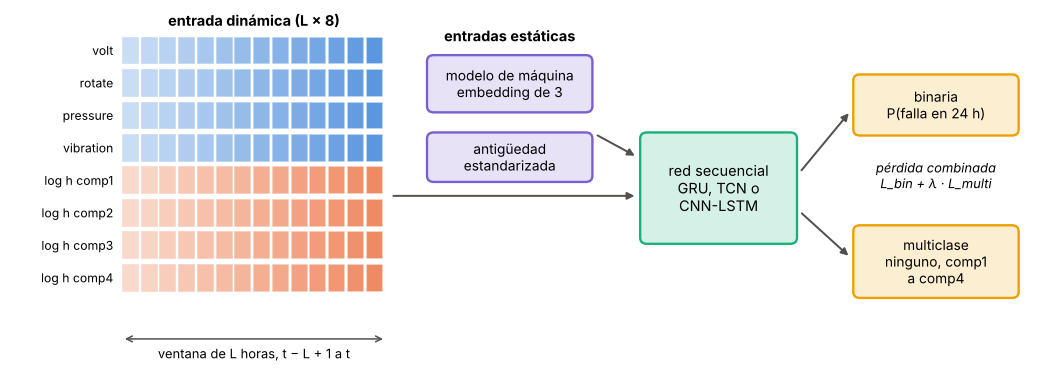

In [7]:
def caja(ax, x, y, w, h, texto, color, fs=9, alpha=0.18):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc=color, ec=color, alpha=alpha, lw=1.5))
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc="none", ec=color, lw=1.5))
    ax.text(x + w / 2, y + h / 2, texto, ha="center", va="center", fontsize=fs)

def flecha(ax, x0, y0, x1, y1):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", color="#52514e", lw=1.3))

fig, ax = plt.subplots(figsize=(12, 4.2))
ax.set_xlim(0, 12); ax.set_ylim(0, 4.6); ax.axis("off")
# rejilla L x C
nombres = ["volt", "rotate", "pressure", "vibration", "log h comp1", "log h comp2", "log h comp3", "log h comp4"]
for j, nom in enumerate(nombres):
    yj = 3.9 - j * 0.42
    color = AZUL if j < 4 else NARANJA
    for i in range(14):
        ax.add_patch(Rectangle((1.3 + i * 0.22, yj), 0.2, 0.36, fc=color, alpha=0.25 + 0.04 * i, ec="white"))
    ax.text(1.2, yj + 0.18, nom, ha="right", va="center", fontsize=8)
ax.annotate("", xy=(4.4, 0.35), xytext=(1.3, 0.35), arrowprops=dict(arrowstyle="<->", color="#52514e"))
ax.text(2.85, 0.1, "ventana de L horas, t − L + 1 a t", ha="center", fontsize=8.5)
ax.text(2.85, 4.4, "entrada dinámica (L × 8)", ha="center", fontsize=9.5, weight="bold")
caja(ax, 4.9, 3.3, 1.9, 0.7, "modelo de máquina\nembedding de 3", MORADO)
caja(ax, 4.9, 2.4, 1.9, 0.6, "antigüedad\nestandarizada", MORADO)
ax.text(5.85, 4.2, "entradas estáticas", ha="center", fontsize=9.5, weight="bold")
caja(ax, 7.4, 1.6, 1.8, 1.4, "red secuencial\nGRU, TCN o\nCNN-LSTM", AQUA, fs=9.5)
flecha(ax, 4.45, 2.2, 7.35, 2.2); flecha(ax, 6.85, 3.0, 7.35, 2.7)
caja(ax, 9.9, 3.0, 1.9, 0.75, "binaria\nP(falla en 24 h)", AMARILLO)
caja(ax, 9.9, 0.9, 1.9, 0.9, "multiclase\nninguno, comp1\na comp4", AMARILLO)
flecha(ax, 9.25, 2.5, 9.85, 3.3); flecha(ax, 9.25, 2.0, 9.85, 1.4)
ax.text(10.85, 2.3, "pérdida combinada\nL_bin + λ · L_multi", ha="center", fontsize=8.5, style="italic")
plt.savefig("figuras/fig1_tensor.png", bbox_inches="tight"); plt.show()

## 4. Línea base de referencia sin errores

Se reentrenan la regresión logística y LightGBM de la entrega 1 con las mismas variables menos los cinco conteos de error (29 variables). Se evalúan con las mismas métricas que las redes para que la comparación sea directa.

**Métricas de esta entrega.**

* **PR-AUC, ROC-AUC y recall con precisión ≥ 0.80**, igual que en la entrega 1.
* **F1 macro por componente**. Se usa una regla de decisión con las dos salidas, hay alerta si la probabilidad binaria supera el umbral de mejor F1 en validación y el componente es el de mayor probabilidad en la salida multiclase. Se reporta el F1 de cada componente y su promedio.
* **Tiempo de anticipación**, horas entre la primera alerta sostenida (probabilidad sobre ese umbral al menos 3 horas seguidas) y la falla real, buscando en las 72 horas previas a cada falla de validación. Se reporta el promedio y el porcentaje de fallas detectadas.
* **Brier**, error cuadrático medio de la probabilidad, para medir la calibración.

In [8]:
X1 = construir_variables(tel, err, man, maq)
conj = particionar(X1.merge(etiquetas, on=["machineID", "datetime"]))
tr1, va1 = conj["train"], conj["val"]
F_REF = [c for c in tr1.columns if c not in ("datetime", "machineID") and not c.startswith("y_") and "cuenta" not in c]
llave = pd.DataFrame({"machineID": D["maquinas"][iv[:, 0]], "datetime": pd.to_datetime(D["horas"][iv[:, 1]])})
va1 = llave.merge(va1, on=["machineID", "datetime"], how="left")  # mismo orden que las ventanas de las redes

kw = dict(n_estimators=500, learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1,
          colsample_bytree=0.8, random_state=SEED, verbose=-1)
lr = lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                           LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED))
resultados, historias, predicciones = [], {}, {}
for nombre, fb, fm in [("Logística (línea base)", lr(), lr()),
                       ("LightGBM (línea base)", LGBMClassifier(**kw), LGBMClassifier(objective="multiclass", **kw))]:
    pb = fb.fit(tr1[F_REF], tr1.y_bin).predict_proba(va1[F_REF])[:, 1]
    pm = fm.fit(tr1[F_REF], tr1.y_multi).predict_proba(va1[F_REF])
    r = evaluar(D, iv, pb, pm, fal, nombre)
    r.update({"arquitectura": nombre.split(" ")[0], "L": np.nan, "estrategia": "-"})
    resultados.append(r); predicciones[nombre] = (pb, pm)
COLS = ["PR-AUC", "ROC-AUC", "recall P≥0.80", "F1 macro comp", "anticipación media (h)", "fallas detectadas %", "Brier"]
print("Variables de la línea base", len(F_REF))
pd.DataFrame(resultados).set_index("modelo")[COLS].round(3)

Variables de la línea base 29


,PR-AUC,ROC-AUC,recall P≥0.80,F1 macro comp,anticipación media (h),fallas detectadas %,Brier
modelo,,,,,,,
Logística (línea base),0.282,0.962,0.009,0.327,29.611,87.156,0.071
LightGBM (línea base),0.923,0.999,0.985,0.856,23.651,100.000,0.003


**Sin los conteos de error LightGBM sigue siendo muy fuerte.** Llega a PR-AUC de 0.923 y detecta el 100 % de las 109 fallas de validación con 23.7 h de anticipación media, mientras la logística cae a 0.282. LightGBM aprovecha las medias móviles de 24 h y las horas desde el último reemplazo, que capturan el salto de los sensores y la rejilla de 15 días de los mantenimientos.

## 5. Arquitecturas

Las tres redes comparten la misma cabeza. El resumen de la secuencia se concatena con el embedding del modelo de máquina y la antigüedad, pasa por una capa densa de 64 unidades con dropout y termina en dos salidas, una binaria y una multiclase de cinco clases.

* **GRU**, una capa recurrente de 64 unidades, se usa el último estado oculto.
* **TCN**, bloques residuales de convoluciones causales dilatadas (kernel 3, dilataciones 1, 2, 4, ...) hasta que el campo receptivo cubre la ventana L, se usa la salida del último paso.
* **CNN-LSTM**, dos convoluciones de 32 filtros con max pooling que reducen la secuencia a L/4 pasos y una LSTM de 64 unidades encima.

**Pérdida combinada.** L = L_bin + λ · L_multi con λ = 0.5. La tarea binaria es la principal y la multiclase funciona como tarea auxiliar que obliga a la representación a distinguir componentes. Se usa λ menor que 1 porque la entropía cruzada de cinco clases tiene una escala mayor que la binaria y, con peso 1, dominaba el gradiente en las primeras pruebas. La búsqueda de hiperparámetros de la sección 8 explora λ entre 0.2 y 1.

**Entrenamiento disciplinado.** Optimizador AdamW (tasa 0.001, weight decay 0.0001), dropout 0.2, recorte de gradiente en 1, lotes de 256 y early stopping con paciencia de 4 épocas sobre la PR-AUC de validación. En cada época se toman 60 000 ventanas nuevas al azar del entrenamiento. Para que la evaluación de cada época sea rápida el early stopping usa una de cada 4 horas de validación, que conserva la prevalencia real, y las métricas finales usan toda la validación.

### Figura 2. Diagrama de las arquitecturas

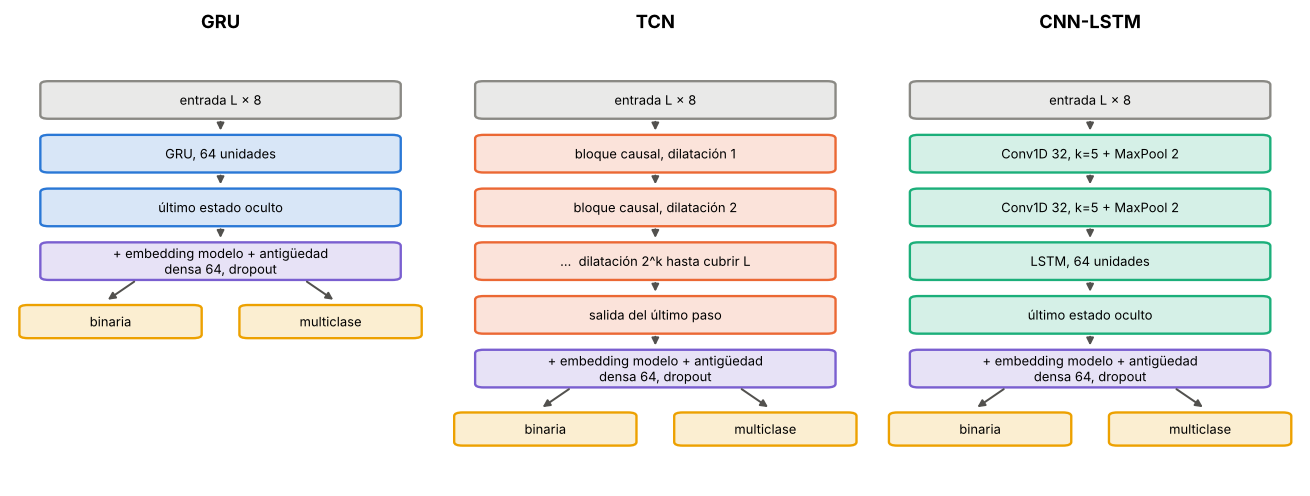

GRU parámetros con L = 72 19,026
TCN parámetros con L = 72 31,794
CNN-LSTM parámetros con L = 72 36,370


In [9]:
fig, axs = plt.subplots(1, 3, figsize=(12, 4.6))
capas = {
    "GRU": [("entrada L × 8", GRIS), ("GRU, 64 unidades", AZUL), ("último estado oculto", AZUL)],
    "TCN": [("entrada L × 8", GRIS), ("bloque causal, dilatación 1", NARANJA), ("bloque causal, dilatación 2", NARANJA),
            ("...  dilatación 2^k hasta cubrir L", NARANJA), ("salida del último paso", NARANJA)],
    "CNN-LSTM": [("entrada L × 8", GRIS), ("Conv1D 32, k=5 + MaxPool 2", AQUA), ("Conv1D 32, k=5 + MaxPool 2", AQUA),
                 ("LSTM, 64 unidades", AQUA), ("último estado oculto", AQUA)],
}
for ax, (nombre, cs) in zip(axs, capas.items()):
    ax.set_xlim(0, 4); ax.set_ylim(0, 10); ax.axis("off"); ax.set_title(nombre, fontsize=12, weight="bold")
    y = 9.0
    for texto, color in cs:
        caja(ax, 0.3, y - 0.8, 3.4, 0.8, texto, color, fs=8.5)
        flecha(ax, 2.0, y - 0.82, 2.0, y - 1.15)
        y -= 1.2
    caja(ax, 0.3, y - 0.8, 3.4, 0.8, "+ embedding modelo + antigüedad\ndensa 64, dropout", MORADO, fs=8.5)
    flecha(ax, 1.2, y - 0.82, 0.9, y - 1.3); flecha(ax, 2.8, y - 0.82, 3.1, y - 1.3)
    caja(ax, 0.1, y - 2.1, 1.7, 0.7, "binaria", AMARILLO, fs=8.5)
    caja(ax, 2.2, y - 2.1, 1.7, 0.7, "multiclase", AMARILLO, fs=8.5)
plt.tight_layout(); plt.savefig("figuras/fig2_arquitecturas.png", bbox_inches="tight"); plt.show()

for arq in ["GRU", "TCN", "CNN-LSTM"]:
    n = sum(p.numel() for p in crear_modelo(arq, 8, 72).parameters())
    print(arq, "parámetros con L = 72", f"{n:,}")

## 6. Experimento 1, arquitectura y longitud de ventana L

Se entrenan las tres arquitecturas con L de 24, 72 y 168 horas usando la pérdida ponderada. La mejor combinación según la PR-AUC de validación se usa en los experimentos siguientes.

In [10]:
EPOCAS, MUESTRAS, PACIENCIA, ENSAYOS = (15, 60000, 4, 15)

def correr(nombre, D_, arq, L, estrategia="ponderada", **kw):
    t0 = time.time()
    m, h = entrenar(D_, arq, L, estrategia, epocas=EPOCAS, muestras_epoca=MUESTRAS, paciencia=PACIENCIA,
                    verbose=False, seed=SEED, **kw)
    pb, pm = predecir(m, D_, D_["idx_val"], L)
    r = evaluar(D_, D_["idx_val"], pb, pm, fal, nombre)
    r.update({"arquitectura": arq, "L": L, "estrategia": estrategia, "épocas": len(h), "minutos": (time.time() - t0) / 60})
    resultados.append(r); historias[nombre] = h; predicciones[nombre] = (pb, pm)
    print(f"{nombre:32s} PR-AUC {r['PR-AUC']:.3f}  F1 macro {r['F1 macro comp']:.3f}  "
          f"épocas {len(h)}  {r['minutos']:.1f} min")
    return m

for arq in ["GRU", "TCN", "CNN-LSTM"]:
    for L in [24, 72, 168]:
        correr(f"{arq} L={L}", D, arq, L)

GRU L=24                         PR-AUC 0.645  F1 macro 0.637  épocas 14  1.0 min


GRU L=72                         PR-AUC 0.680  F1 macro 0.642  épocas 12  2.6 min


GRU L=168                        PR-AUC 0.678  F1 macro 0.641  épocas 14  7.4 min


TCN L=24                         PR-AUC 0.613  F1 macro 0.635  épocas 15  1.6 min


TCN L=72                         PR-AUC 0.687  F1 macro 0.676  épocas 15  6.9 min


TCN L=168                        PR-AUC 0.675  F1 macro 0.661  épocas 14  17.8 min


CNN-LSTM L=24                    PR-AUC 0.593  F1 macro 0.586  épocas 9  0.3 min


CNN-LSTM L=72                    PR-AUC 0.687  F1 macro 0.668  épocas 14  1.1 min


CNN-LSTM L=168                   PR-AUC 0.720  F1 macro 0.714  épocas 15  2.6 min


In [11]:
res = pd.DataFrame(resultados)
exp1 = res[res.estrategia == "ponderada"]
display(exp1.pivot(index="arquitectura", columns="L", values="PR-AUC").round(3))
display(exp1.pivot(index="arquitectura", columns="L", values="F1 macro comp").round(3))
mejor = exp1.loc[exp1["PR-AUC"].idxmax()]
ARQ, L_MEJOR = mejor.arquitectura, int(mejor.L)
print("Mejor combinación", ARQ, "con L =", L_MEJOR)

L,24.0,72.0,168.0
arquitectura,,,
CNN-LSTM,0.593,0.687,0.720
GRU,0.645,0.680,0.678
TCN,0.613,0.687,0.675


L,24.0,72.0,168.0
arquitectura,,,
CNN-LSTM,0.586,0.668,0.714
GRU,0.637,0.642,0.641
TCN,0.635,0.676,0.661


Mejor combinación CNN-LSTM con L = 168


### Figura 3. Efecto de la longitud de ventana L

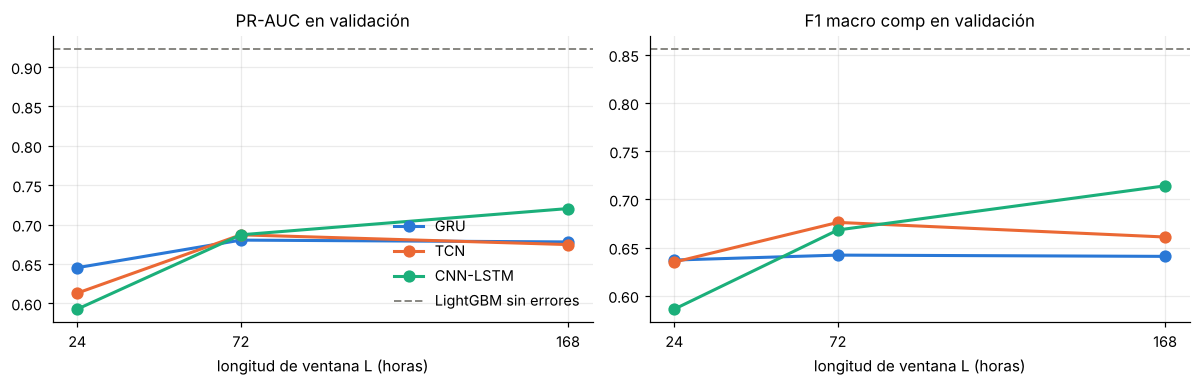

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for arq in ["GRU", "TCN", "CNN-LSTM"]:
    d = exp1[exp1.arquitectura == arq].sort_values("L")
    axs[0].plot(d.L, d["PR-AUC"], "o-", color=COL_ARQ[arq], label=arq, ms=7)
    axs[1].plot(d.L, d["F1 macro comp"], "o-", color=COL_ARQ[arq], label=arq, ms=7)
base = res.set_index("modelo").loc["LightGBM (línea base)"]
for ax, m in zip(axs, ["PR-AUC", "F1 macro comp"]):
    ax.axhline(base[m], color=GRIS, ls="--", lw=1.3, label="LightGBM sin errores")
    ax.set_xticks([24, 72, 168]); ax.set_xlabel("longitud de ventana L (horas)"); ax.set_title(m + " en validación")
axs[0].legend(loc="lower right")
plt.tight_layout(); plt.savefig("figuras/fig3_efecto_L.png", bbox_inches="tight"); plt.show()

**Las ventanas largas ayudan, sobre todo a la CNN-LSTM.** Pasar de 24 a 72 h sube la PR-AUC de las tres redes, porque con 24 h la ventana no alcanza a ver el inicio del salto del sensor, que ocurre unas 48 h antes de la falla. Con 168 h la CNN-LSTM sigue mejorando hasta 0.720, mientras GRU y TCN se estancan cerca de 0.68. Probablemente el pooling ayuda porque reduce las 168 horas a 42 pasos y la LSTM recuerda mejor una secuencia corta. Ninguna red se acerca a la línea base de 0.923.

## 7. Experimento 2, estrategia de desbalance

Con la mejor arquitectura y ventana se comparan tres estrategias.

* **Pérdida ponderada**, muestreo con la prevalencia natural, peso de la clase positiva igual a la razón negativas por positiva (cerca de 48) y pesos por clase en la multiclase.
* **Focal loss**, muestreo natural y pérdida focal con γ = 2 y α = 0.75 en las dos salidas, que reduce el peso de los ejemplos fáciles.
* **Submuestreo de horas sanas**, cada época toma ventanas pre-falla y cuatro sanas por cada una, con pérdida sin pesos.

In [13]:
for est in ["focal", "submuestreo"]:
    correr(f"{ARQ} L={L_MEJOR} {est}", D, ARQ, L_MEJOR, est)
res = pd.DataFrame(resultados)
exp2 = res[(res.arquitectura == ARQ) & (res.L == L_MEJOR)].set_index("estrategia")
display(exp2[COLS].round(3))
EST = exp2["PR-AUC"].idxmax()
print("Mejor estrategia", EST)

CNN-LSTM L=168 focal             PR-AUC 0.671  F1 macro 0.675  épocas 14  2.5 min


CNN-LSTM L=168 submuestreo       PR-AUC 0.743  F1 macro 0.709  épocas 15  2.5 min


,PR-AUC,ROC-AUC,recall P≥0.80,F1 macro comp,anticipación media (h),fallas detectadas %,Brier
estrategia,,,,,,,
ponderada,0.720,0.993,0.207,0.714,24.543,96.330,0.013
focal,0.671,0.994,0.123,0.675,25.510,91.743,0.013
submuestreo,0.743,0.994,0.398,0.709,26.051,90.826,0.011


Mejor estrategia submuestreo


### Figura 4. Calibración de las probabilidades según la estrategia de desbalance

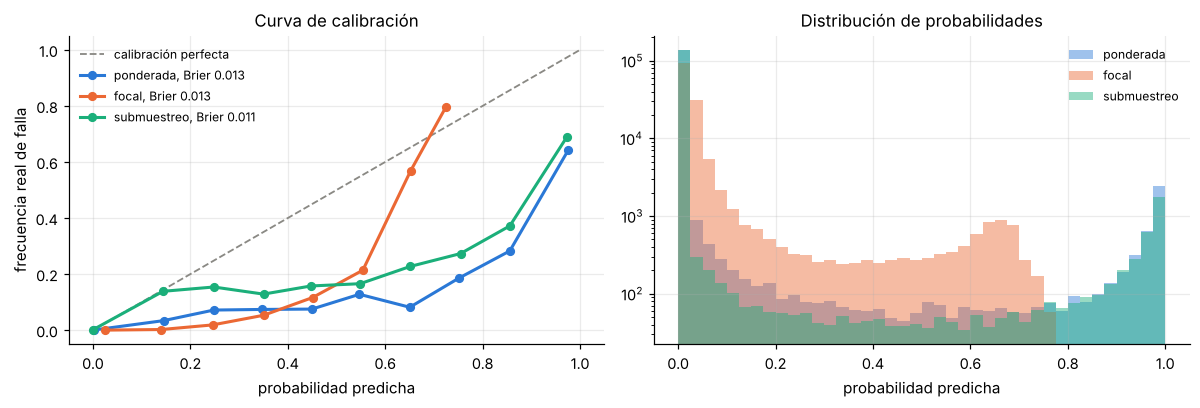

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
yv = D["y_bin"][iv[:, 0], iv[:, 1]].numpy()
axs[0].plot([0, 1], [0, 1], color=GRIS, ls="--", lw=1.2, label="calibración perfecta")
colores = {"ponderada": AZUL, "focal": NARANJA, "submuestreo": AQUA}
for est, nombre in zip(exp2.index, exp2.modelo):
    pb = predicciones[nombre][0]
    fr, mp = calibration_curve(yv, pb, n_bins=10, strategy="uniform")
    axs[0].plot(mp, fr, "o-", color=colores[est], label=f"{est}, Brier {exp2.loc[est, 'Brier']:.3f}", ms=5)
    axs[1].hist(pb, bins=40, range=(0, 1), color=colores[est], alpha=0.45, label=est)
axs[0].set_xlabel("probabilidad predicha"); axs[0].set_ylabel("frecuencia real de falla"); axs[0].legend(fontsize=8)
axs[0].set_title("Curva de calibración")
axs[1].set_yscale("log"); axs[1].set_xlabel("probabilidad predicha"); axs[1].set_title("Distribución de probabilidades")
axs[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("figuras/fig4_calibracion.png", bbox_inches="tight"); plt.show()

**El submuestreo dio la mejor PR-AUC y la focal loss la peor.** El submuestreo llega a 0.743, contra 0.720 de la pérdida ponderada y 0.671 de la focal. Ninguna estrategia queda bien calibrada. La ponderada y el submuestreo empujan muchas ventanas a probabilidades cercanas a 1 y sobrestiman el riesgo, ya que entrenan como si las fallas fueran mucho más comunes de lo que son. La focal loss reparte las probabilidades en valores intermedios y subestima el riesgo por debajo de 0.6. Para usar estas probabilidades como riesgo real habría que recalibrarlas en validación, por ejemplo con Platt o con regresión isotónica.

## 8. Experimento 3, búsqueda de hiperparámetros con presupuesto declarado

**Presupuesto.** Optuna con muestreador TPE y 15 ensayos sobre la mejor arquitectura, ventana y estrategia. Cada ensayo entrena 4 épocas de 30 000 ventanas y se evalúa con la PR-AUC de la submuestra de validación. Se exploran las unidades ocultas (32, 64 o 128), la tasa de aprendizaje (0.0003 a 0.003), el dropout (0 a 0.4), el weight decay (0.00001 a 0.001) y λ (0.2 a 1). Con la mejor configuración se reentrena el modelo final con el presupuesto completo.

In [15]:
def objetivo(trial):
    p = {"hidden": trial.suggest_categorical("hidden", [32, 64, 128]),
         "lr": trial.suggest_float("lr", 3e-4, 3e-3, log=True),
         "dropout": trial.suggest_float("dropout", 0.0, 0.4),
         "weight_decay": trial.suggest_float("weight_decay", 1e-5, 1e-3, log=True),
         "lam": trial.suggest_float("lam", 0.2, 1.0)}
    _, h = entrenar(D, ARQ, L_MEJOR, EST, epocas=2 if RAPIDO else 4, muestras_epoca=4000 if RAPIDO else 30000,
                    paciencia=10, verbose=False, seed=SEED, **p)
    return h.pr_auc_val.max()

t0 = time.time()
estudio = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
estudio.optimize(objetivo, n_trials=ENSAYOS)
print(f"Búsqueda terminada en {(time.time() - t0) / 60:.1f} min")
ensayos = estudio.trials_dataframe()[["number", "value", "params_hidden", "params_lr", "params_dropout",
                                      "params_weight_decay", "params_lam"]].sort_values("value", ascending=False)
ensayos.to_csv("resultados_e2/optuna_ensayos.csv", index=False)
display(ensayos.head(5).round(4))
MEJORES = estudio.best_params
print("Mejores hiperparámetros", ", ".join(f"{k} = {v:.4g}" if isinstance(v, float) else f"{k} = {v}" for k, v in MEJORES.items()))

Búsqueda terminada en 7.0 min


,number,value,params_hidden,params_lr,params_dropout,params_weight_decay,params_lam
7,7,0.7035,64,0.0026,0.3579,0.0002,0.9375
11,11,0.6714,64,0.0027,0.2257,0.0003,0.3796
12,12,0.6542,64,0.0026,0.2099,0.0003,0.4697
0,0,0.6500,64,0.0012,0.0624,0.0000,0.2465
14,14,0.6383,64,0.0013,0.1645,0.0002,0.3083


Mejores hiperparámetros hidden = 64, lr = 0.00261, dropout = 0.3579, weight_decay = 0.000157, lam = 0.9375


In [16]:
modelo_final = correr(f"{ARQ} L={L_MEJOR} {EST} ajustado", D, ARQ, L_MEJOR, EST, **MEJORES)
NOMBRE_FINAL = f"{ARQ} L={L_MEJOR} {EST} ajustado"

CNN-LSTM L=168 submuestreo ajustado PR-AUC 0.757  F1 macro 0.728  épocas 13  2.3 min


### Figura 5. Curvas de aprendizaje

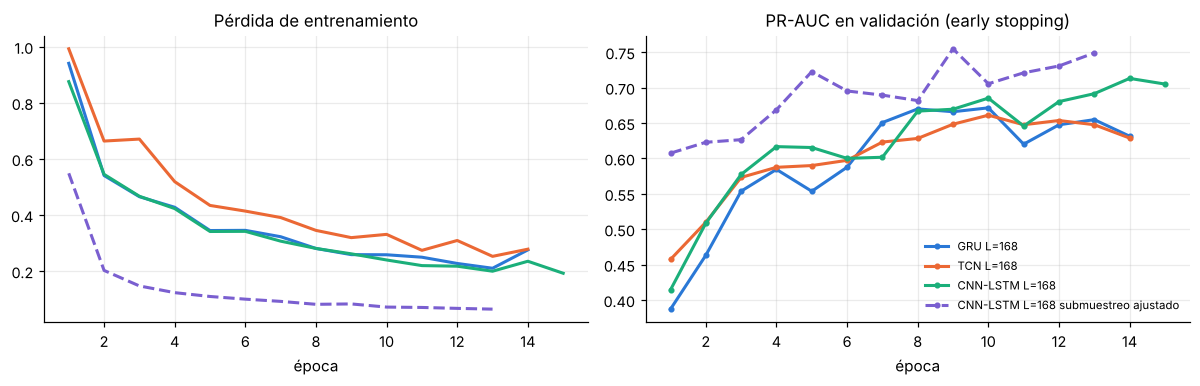

In [17]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
curvas = [(f"{a} L={L_MEJOR}", COL_ARQ[a], "-") for a in ["GRU", "TCN", "CNN-LSTM"]] + [(NOMBRE_FINAL, MORADO, "--")]
for nombre, color, ls in curvas:
    h = historias[nombre]
    axs[0].plot(h.epoca, h.perdida_train, color=color, ls=ls, label=nombre)
    axs[1].plot(h.epoca, h.pr_auc_val, color=color, ls=ls, label=nombre, marker="o", ms=3)
axs[0].set_title("Pérdida de entrenamiento"); axs[0].set_xlabel("época")
axs[1].set_title("PR-AUC en validación (early stopping)"); axs[1].set_xlabel("época")
axs[1].legend(fontsize=7.5, loc="lower right")
plt.tight_layout(); plt.savefig("figuras/fig5_curvas_aprendizaje.png", bbox_inches="tight"); plt.show()

**La búsqueda de hiperparámetros sumó poco y el entrenamiento es inestable.** La mejor configuración (64 unidades, tasa 0.0026, dropout 0.36 y λ = 0.94) llevó a la CNN-LSTM con submuestreo de 0.743 a 0.757. La búsqueda prefirió un λ alto, lo que sugiere que la tarea multiclase sí ayuda a la binaria. La PR-AUC de validación sube y baja varias centésimas entre épocas, por eso el early stopping guarda el mejor estado y no el último. La pérdida del modelo ajustado es más baja porque entrena con lotes balanceados y no es comparable en escala con las demás.

## 9. Comparación contra la línea base

Tabla comparativa en validación de las líneas base sin errores, las tres arquitecturas con la mejor ventana y el modelo final ajustado.

In [18]:
res = pd.DataFrame(resultados)
filas = ["Logística (línea base)", "LightGBM (línea base)"] + [f"{a} L={L_MEJOR}" for a in ["GRU", "TCN", "CNN-LSTM"]] + [NOMBRE_FINAL]
tabla = res.set_index("modelo").loc[filas]
display(tabla[COLS].round(3))
display(tabla[[f"F1 {c}" for c in COMPONENTES]].round(3))
res.round(4).to_csv("resultados_e2/resultados_validacion.csv", index=False)

,PR-AUC,ROC-AUC,recall P≥0.80,F1 macro comp,anticipación media (h),fallas detectadas %,Brier
modelo,,,,,,,
Logística (línea base),0.282,0.962,0.009,0.327,29.611,87.156,0.071
LightGBM (línea base),0.923,0.999,0.985,0.856,23.651,100.000,0.003
GRU L=168,0.678,0.993,0.154,0.641,25.041,89.908,0.019
TCN L=168,0.675,0.994,0.110,0.661,25.040,92.661,0.020
CNN-LSTM L=168,0.720,0.993,0.207,0.714,24.543,96.330,0.013
CNN-LSTM L=168 submuestreo ajustado,0.757,0.993,0.415,0.728,26.495,96.330,0.011


,F1 comp1,F1 comp2,F1 comp3,F1 comp4
modelo,,,,
Logística (línea base),0.209,0.375,0.428,0.298
LightGBM (línea base),0.748,0.899,0.857,0.920
GRU L=168,0.527,0.696,0.639,0.702
TCN L=168,0.555,0.681,0.737,0.671
CNN-LSTM L=168,0.554,0.748,0.827,0.726
CNN-LSTM L=168 submuestreo ajustado,0.590,0.772,0.807,0.742


### Figura 6. Curvas precisión recall y tiempo de anticipación

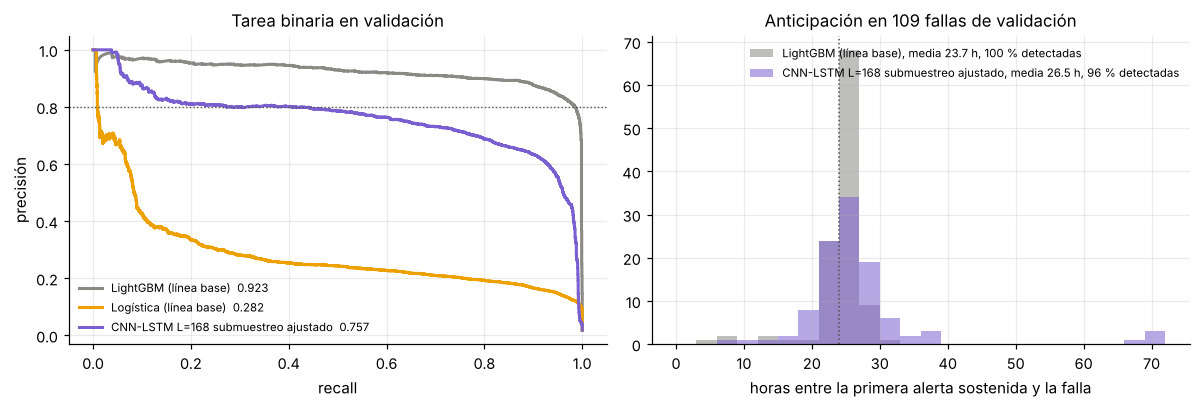

In [19]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
comparar = [("LightGBM (línea base)", GRIS), ("Logística (línea base)", AMARILLO), (NOMBRE_FINAL, MORADO)]
for nombre, color in comparar:
    pb = predicciones[nombre][0]
    prec, rec, _ = precision_recall_curve(yv, pb)
    axs[0].plot(rec, prec, color=color, label=f"{nombre}  {tabla.loc[nombre, 'PR-AUC']:.3f}")
axs[0].axhline(0.80, color="#52514e", lw=0.9, ls=":")
axs[0].set_xlabel("recall"); axs[0].set_ylabel("precisión"); axs[0].set_title("Tarea binaria en validación")
axs[0].legend(fontsize=7.5, loc="lower left")
for nombre, color in [("LightGBM (línea base)", GRIS), (NOMBRE_FINAL, MORADO)]:
    pb = predicciones[nombre][0]
    u = umbral_alerta(yv, pb)
    antic, frac, n = tiempo_anticipacion(D, iv, pb, fal, u)
    axs[1].hist(antic, bins=range(0, 75, 3), color=color, alpha=0.55,
                label=f"{nombre}, media {antic.mean():.1f} h, {frac * 100:.0f} % detectadas")
axs[1].axvline(24, color="#52514e", ls=":", lw=1)
axs[1].set_xlabel("horas entre la primera alerta sostenida y la falla"); axs[1].set_title(f"Anticipación en {n} fallas de validación")
axs[1].legend(fontsize=7.5)
plt.tight_layout(); plt.savefig("figuras/fig6_pr_anticipacion.png", bbox_inches="tight"); plt.show()

**La red queda por debajo de LightGBM en casi todo el rango.** Con precisión de 0.80 la CNN-LSTM ajustada recupera el 42 % de las horas positivas, contra 98 % de LightGBM. En anticipación sí es comparable, detecta el 96 % de las fallas con 26.5 h de anticipación media contra 23.7 h de LightGBM. Probablemente esa ventaja viene de alertas que se encienden con el salto del sensor 48 h antes, las mismas que bajan su precisión.

## 10. Experimento con canales de error

Se repite el modelo final agregando los cinco indicadores horarios de error que pide el punto 2.1. Este resultado no se usa para elegir modelo, solo muestra el efecto del patrón de la simulación descrito en la entrega 1.

In [20]:
D_err = construir_tensor(tel, err, man, maq, etiquetas, con_errores=True)
correr(f"{ARQ} L={L_MEJOR} {EST} con errores", D_err, ARQ, L_MEJOR, EST, **MEJORES)
res = pd.DataFrame(resultados)
display(res.set_index("modelo").loc[[NOMBRE_FINAL, f"{ARQ} L={L_MEJOR} {EST} con errores"]][COLS].round(3))
res.round(4).to_csv("resultados_e2/resultados_validacion.csv", index=False)

CNN-LSTM L=168 submuestreo con errores PR-AUC 0.996  F1 macro 0.955  épocas 12  2.1 min


,PR-AUC,ROC-AUC,recall P≥0.80,F1 macro comp,anticipación media (h),fallas detectadas %,Brier
modelo,,,,,,,
CNN-LSTM L=168 submuestreo ajustado,0.757,0.993,0.415,0.728,26.495,96.330,0.011
CNN-LSTM L=168 submuestreo con errores,0.996,1.000,0.995,0.955,23.815,99.083,0.001


**Con los canales de error la red también llega casi a 1.** La misma CNN-LSTM sube de 0.757 a 0.996 de PR-AUC y de 0.728 a 0.955 de F1 macro. Esto confirma que el resultado perfecto de la entrega 1 no dependía de LightGBM sino del patrón de la simulación, ya que cualquier modelo con acceso al error de 24 h antes lo aprovecha.

## 11. Discusión, ¿supera el deep learning a la línea base?

**No, el deep learning no supera a la línea base.** El mejor modelo secuencial, una CNN-LSTM con ventana de 168 h, submuestreo y búsqueda de hiperparámetros, llega a PR-AUC de 0.757 y F1 macro de 0.728, contra 0.923 y 0.856 de LightGBM con las mismas fuentes de información. Sí supera por mucho a la regresión logística (0.282 y 0.327).

Creemos que hay cuatro razones.

1. **Las variables de la línea base ya resumen bien la señal.** La falla se anuncia con un escalón en un sensor unas 48 h antes. Las medias móviles de 24 h y las horas desde el último reemplazo capturan justo eso, y LightGBM solo tiene que combinarlas. La red tiene que aprender esos mismos resúmenes desde la serie cruda.
2. **Hay pocos eventos para aprender.** Entrenamiento tiene 522 fallas, y como cada una genera 24 horas positivas muy parecidas entre sí, la red ve en realidad pocos ejemplos distintos. Los modelos de deep learning suelen necesitar mucha más variedad.
3. **La etiqueta es ambigua dentro del escalón.** El sensor se ve igual a 48 y a 24 h de la falla, pero solo las últimas 24 h son positivas. Lo que permite separarlas es el ciclo de mantenimiento de 15 días, que LightGBM lee directo de las horas desde el reemplazo y la red tiene que inferir dentro de la ventana.
4. **El presupuesto de cómputo fue limitado.** Cada época usa 60 000 de las 580 200 ventanas y la búsqueda tuvo 15 ensayos cortos. Con más entrenamiento la brecha podría reducirse, pero difícilmente desaparecería.

Lo que sí aporta la red es una anticipación un poco mayor (26.5 h contra 23.7 h) y la capacidad de trabajar con la serie sin diseñar variables a mano, algo más valioso en una planta real con más datos y patrones menos limpios. Para la semana 3 conviene probar un modelo que combine las variables de la línea base con la representación de la red y recalibrar las probabilidades antes de definir la política de mantenimiento.